# NER preflight and pilot

Read `reports/NER_PREFLIGHT_AND_PILOT.md` for policies and limitations. The pilot uses fit/checkpoint only; calibration and final audit have no NER model scores. Test inference below checks structure without labels or F1.

In [5]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
BASE = Path.cwd() if (Path.cwd() / 'reports/ner_pilot_results.json').exists() else Path.cwd() / 'assignment3'
BASE = BASE.resolve()
audit = json.loads((BASE / 'reports/ner_preprocessing_audit.json').read_text(encoding='utf-8'))
display(pd.DataFrame(audit['by_partition']).T)

,rows,gold_spans,trimmed_whitespace_spans,tokens,long_text_rows,alignment_incompatible_rows,roundtrip_passed_rows,roundtrip_passed_spans,partial_token_boundary
fit,999948.0,341799.0,203.0,18055911.0,0.0,1485.0,998463.0,338824.0,1501.0
excluded_overlap,52.0,11.0,0.0,886.0,0.0,0.0,52.0,11.0,NaN
audit,4000.0,1322.0,1.0,72628.0,0.0,7.0,3993.0,1315.0,7.0
checkpoint,4000.0,1328.0,1.0,72939.0,0.0,4.0,3996.0,1323.0,4.0
calibration,2000.0,654.0,1.0,36210.0,0.0,4.0,1996.0,644.0,4.0


In [6]:
pilot = json.loads((BASE / 'reports/ner_pilot_results.json').read_text())
print('Tiny-set memorization passed:', pilot['tiny_memorization']['passed'])
display(pd.DataFrame({'Fit monitor': pilot['best_train_monitor'], 'Checkpoint': pilot['best_checkpoint']}))

Tiny-set memorization passed: True


,Fit monitor,Checkpoint
tp,585.000000,887.000000
fp,231.000000,917.000000
fn,38.000000,431.000000
precision,0.716912,0.491685
recall,0.939005,0.672989
f1,0.813065,0.568226
exact_raw_span_f1,0.800275,0.562540
exact_trimmed_span_f1,0.800275,0.562540
unweighted_token_ce,0.023335,0.068723
ce_tokens,37271.000000,72831.000000


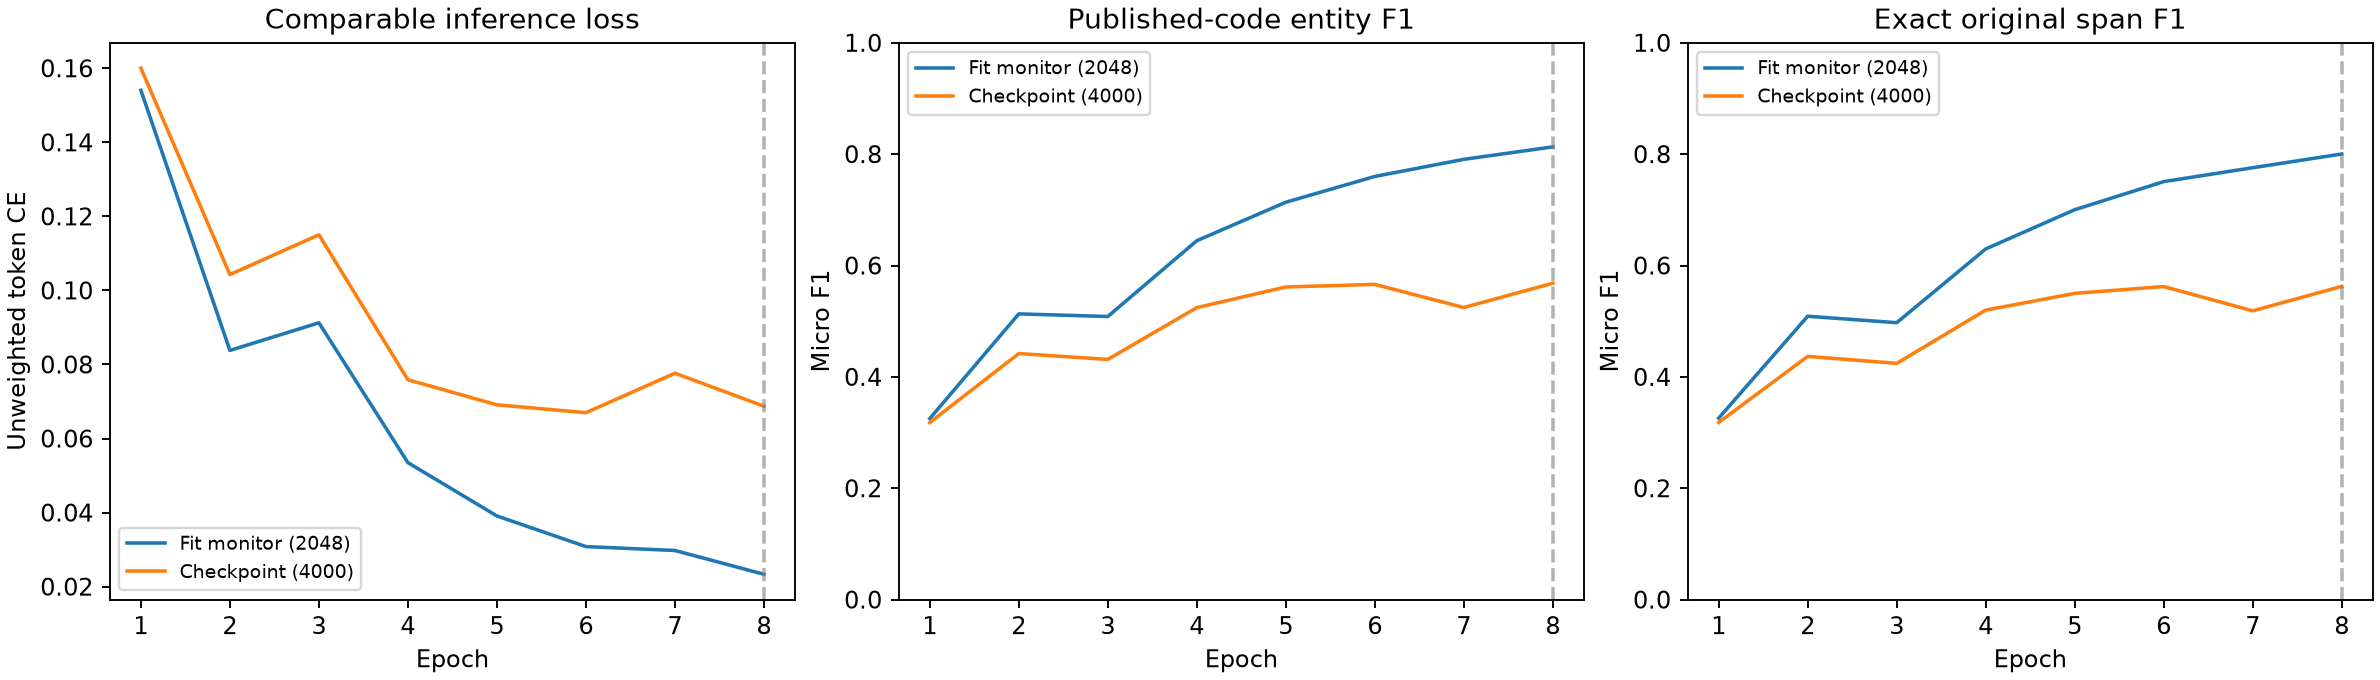

In [7]:
display(Image(filename=str(BASE / 'figures/ner_pilot_learning.png')))

In [8]:
long_checks = json.loads((BASE / 'reports/ner_long_text_checks.json').read_text())
display(pd.Series(long_checks))
print('No test quality metric was computed.')

No test quality metric was computed.


rows                                                                              477
long_text_rows                                                                     83
total_windows                                                                     598
checked_token_positions                                                         35679
all_positions_covered                                                            True
maximum_tokens                                                                    626
finite_normalized_probabilities                                                  True
all_prediction_offsets_in_bounds                                                 True
predicted_entities                                                               1100
orphan_I_repaired                                                                  40
model_sha256                        ca15bc6e9e03560b6674355fa7070f86a32ea1a320d229...
no_test_labels_read                                   

## Reproduction

Run the audit, pilot, and inference scripts from the report. Training weights are local under `outputs/`; original datasets and frozen splits are unchanged.